# 실습 06 · 학습·추론·Sampling (기본필수)

LLM은 마지막에 다음 Token 후보마다 **점수(Logit)** 를 냅니다. 이 점수를 **확률**로 바꾸고, 그중 하나를 **고르는** 과정을 따라갑니다.

`Logit [2, 1, 0]` → `Softmax 확률` → `Temperature로 분포 조절` → `Greedy 선택`

### 사용 방법
1. **결과는 이미 셀 아래에 저장되어 있습니다.** 읽기만 해도 흐름을 따라갈 수 있어요.
2. 직접 돌려 보려면 `파일 → Drive에 사본 저장`으로 내 사본을 만드세요.
3. 맨 위 **⚙️ 준비 셀을 먼저 한 번 실행**한 뒤, 보고 싶은 구간의 셀을 실행하세요. 각 구간은 준비 셀만 있으면 따로 실행됩니다.
4. **✏️ 표시 셀**은 오른쪽 슬라이더의 값을 바꾸고 실행해 보세요. 코드의 값도 함께 바뀝니다.

In [1]:
#@title ⚙️ 먼저 실행하세요 — 실습 공통 코드 준비
# ── 원본: 20261113/mentor/01_basic/common/support.py (그대로 포함) ──
"""강의 공통 오프라인 계산 도구: 실제 사전학습 LLM이 아닙니다.

교육용 정규표현식 토큰화·작은 벡터·가중치 계산만 제공합니다.
Transformer의 tokenizer/embedding 품질을 이 도구로 평가할 수 없습니다.
"""
from pathlib import Path
import json
import math
import re
import torch

DATA = [
    {"id":"A", "title":"실습 파일 보관", "content":"실습 파일은 개인 폴더에 보관합니다.", "category":"learning"},
    {"id":"B", "title":"서버 실행", "content":"프로젝트 폴더에서 서버를 실행합니다.", "category":"environment"},
    {"id":"C", "title":"질문 작성", "content":"오류 메시지와 시도한 작업을 함께 적습니다.", "category":"learning"},
]
SPECIAL = ["[PAD]", "[UNK]", "[BOS]", "[EOS]"]

def words(text: str) -> list[str]:
    """교육용: 한글 연속 글자/영문/숫자/문장부호 분리. 서브워드 토크나이저가 아님."""
    return re.findall(r'[가-힣]+|[A-Za-z]+|\d+|[^\w\s]', text)

class ToyTokenizer:
    """BERT tokenizer 대체가 아닌, 오프라인 개념 확인용 규칙 기반 어휘표."""
    def __init__(self, corpus):
        wordset=sorted({word for line in corpus for word in words(line)})
        self.vocab={tok:i for i,tok in enumerate(SPECIAL + wordset)}
        self.reverse={i:t for t,i in self.vocab.items()}

    def encode(self, text: str, max_length=None, padding_to=None):
        raw=words(text)
        tokens=["[BOS]"]+raw+["[EOS]"]
        truncated=False
        if max_length is not None:
            if max_length<2: raise ValueError("BOS/EOS를 포함하려면 max_length>=2")
            if len(tokens)>max_length:
                tokens=tokens[:max_length-1]+["[EOS]"]
                truncated=True
        valid=len(tokens)
        if padding_to is not None:
            if padding_to<valid: raise ValueError("padding_to must be >= valid length")
            tokens=tokens+["[PAD]"]*(padding_to-valid)
        ids=[self.vocab.get(t,self.vocab["[UNK]"]) for t in tokens]
        mask=[0 if t=="[PAD]" else 1 for t in tokens]
        return {"tokens":tokens,"input_ids":ids,"attention_mask":mask,
                "valid_length":valid,"truncated":truncated,"original_length":len(raw)+2}

    def batch(self, texts, max_length=None):
        items=[self.encode(t,max_length=max_length) for t in texts]
        max_size=max(len(i["input_ids"]) for i in items)
        return [self.encode(t,max_length=max_length,padding_to=max_size) for t in texts]

def context_budget(window, parts:dict, output_reserved:int):
    used=sum(parts.values())
    return {"window":window,"input_used":used,"output_reserved":output_reserved,
            "remaining":window-used-output_reserved,
            "fits":used+output_reserved<=window}

def cosine(a,b):
    a=torch.as_tensor(a,dtype=torch.float32)
    b=torch.as_tensor(b,dtype=torch.float32)
    return float(torch.nn.functional.cosine_similarity(a,b,dim=0))

def attention(q,k,v,causal=True):
    q=torch.as_tensor(q,dtype=torch.float32)
    k=torch.as_tensor(k,dtype=torch.float32)
    v=torch.as_tensor(v,dtype=torch.float32)
    scores=q@k.T/math.sqrt(q.shape[-1])
    mask=torch.triu(torch.ones_like(scores,dtype=torch.bool),diagonal=1)
    weights=torch.softmax(scores.masked_fill(mask,float('-inf')) if causal else scores,dim=-1)
    return scores,weights,weights@v,mask

def write_json(path, data):
    p=Path(path);p.parent.mkdir(exist_ok=True,parents=True)
    p.write_text(json.dumps(data,ensure_ascii=False,indent=2),encoding='utf-8')

def write_md(path,text):
    p=Path(path);p.parent.mkdir(exist_ok=True,parents=True)
    p.write_text(text,encoding='utf-8')

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

# ── 노트북 전용 준비 ──
import pandas as pd
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_num_threads(1)

# 실습 입력 (main.py와 같은 값): 다음 Token 후보 3개의 점수
logits = torch.tensor([2.0, 1.0, 0.0])
labels = ["출력A", "출력B", "출력C"]
PLOT_LABELS = ["A", "B", "C"]          # 그래프용 (Colab 한글 폰트 없음)

def bar(probs, title, ax=None):
    """후보별 확률 막대그래프"""
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 3))
    p = probs.tolist()
    ax.bar(PLOT_LABELS, p, color=["C0", "C1", "C2"])
    for i, val in enumerate(p):
        ax.text(i, val + 0.02, f"{val:.3f}", ha="center")
    ax.set_ylim(0, 1.1); ax.set_ylabel("probability"); ax.set_title(title)
    if show:
        plt.show()

print("준비 완료 ✅  logits:", logits.tolist())

준비 완료 ✅  logits: [2.0, 1.0, 0.0]


## 0. 후보와 점수(Logit)
점수가 클수록 그 후보가 다음 Token일 가능성이 높다는 뜻입니다. 하지만 **아직 확률은 아닙니다.**

In [2]:
pd.DataFrame({"후보": labels, "Logit": logits.tolist()})

,후보,Logit
0,출력A,2.0
1,출력B,1.0
2,출력C,0.0


## B01. Softmax: 점수 → 확률

$$p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

### B01-1. 한 단계씩 계산

In [3]:
exp = logits.exp()
print("e^Logit:", exp.round(decimals=4).tolist())

e^Logit: [7.389100074768066, 2.7183001041412354, 1.0]


In [4]:
total = exp.sum()
print("합계   :", round(total.item(), 4))
print("나누기 :", (exp / total).round(decimals=4).tolist())

합계   : 11.1073
나누기 : [0.6651999950408936, 0.24469999969005585, 0.09000000357627869]


### B01-2. `torch.softmax`로 계산 (`main.py`와 같은 코드)

In [5]:
prob = torch.softmax(logits, dim=0)
pd.DataFrame({"후보": labels, "Logit": logits.tolist(), "확률": prob.round(decimals=3).tolist()})

,후보,Logit,확률
0,출력A,2.0,0.665
1,출력B,1.0,0.245
2,출력C,0.0,0.090


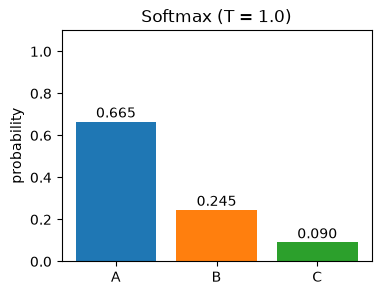

In [6]:
bar(prob, "Softmax (T = 1.0)")

In [7]:
assert torch.isclose(prob.sum(), torch.tensor(1.0), atol=1e-6)
assert torch.allclose(prob, logits.exp() / logits.exp().sum())
print("B01 통과 ✅ 확률 합 =", round(prob.sum().item(), 6), " 예상 [0.665, 0.245, 0.090]")

B01 통과 ✅ 확률 합 = 1.0  예상 [0.665, 0.245, 0.090]


## B02. Temperature: 분포를 뾰족하게 / 평평하게

Logit을 T로 나눈 뒤 Softmax를 합니다.
- **T < 1**: 점수 차이가 커져서 1등에 집중 (더 일정한 답)
- **T > 1**: 점수 차이가 줄어서 평평해짐 (더 다양한 답)

In [8]:
for t in (0.5, 1.0, 2.0):
    print(f"T={t}: Logit/T = {(logits / t).tolist()}")

T=0.5: Logit/T = [4.0, 2.0, 0.0]
T=1.0: Logit/T = [2.0, 1.0, 0.0]
T=2.0: Logit/T = [1.0, 0.5, 0.0]


In [9]:
temperature_results = {str(t): torch.softmax(logits / t, dim=0).tolist() for t in (0.5, 1.0, 2.0)}
pd.DataFrame(temperature_results, index=labels).round(3)

,0.5,1.0,2.0
출력A,0.867,0.665,0.506
출력B,0.117,0.245,0.307
출력C,0.016,0.090,0.186


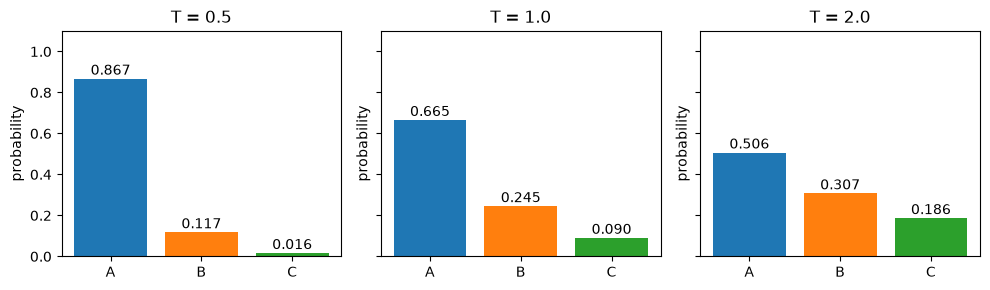

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, t in zip(axes, (0.5, 1.0, 2.0)):
    bar(torch.softmax(logits / t, dim=0), f"T = {t}", ax=ax)
plt.tight_layout(); plt.show()

### ✏️ B02 직접 해 보기 — Temperature를 움직여 보세요

T = 1.0: 1등(출력A) 확률 0.665, 꼴등(출력C) 확률 0.090


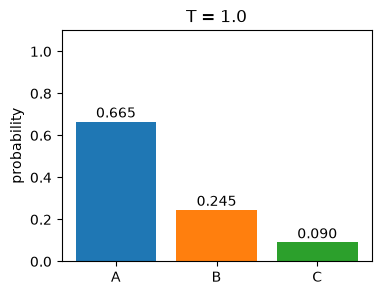

In [11]:
#@title ✏️ Temperature를 바꿔 보세요
temperature = 1.0  #@param {type:"slider", min:0.1, max:5, step:0.1}

p = torch.softmax(logits / temperature, dim=0)
print(f"T = {temperature}: 1등(출력A) 확률 {p[0].item():.3f}, 꼴등(출력C) 확률 {p[2].item():.3f}")
bar(p, f"T = {temperature}")

## B03. 다음 Token 고르기와 학습/추론 차이

### B03-1. Greedy: 확률이 가장 큰 후보

In [12]:
prob = torch.softmax(logits, dim=0)
selected_index = int(torch.argmax(prob).item())
selected_token = labels[selected_index]
print("선택:", selected_index, selected_token)
assert selected_token == "출력A"
print("B03 통과 ✅")

선택: 0 출력A
B03 통과 ✅


### B03-2. 실험: Sampling은 확률대로 뽑는다
Greedy는 항상 같은 답을 고르지만, Sampling은 확률에 따라 뽑기 때문에 **실행할 때마다 달라질 수 있습니다.** 시드(seed)를 고정하면 같은 결과가 나옵니다. (응용·심화 내용 미리 보기)

In [13]:
#@title ✏️ 시드와 Temperature를 바꿔 100번 뽑아 보세요
seed = 42  #@param {type:"integer"}
temperature = 1.0  #@param {type:"slider", min:0.1, max:5, step:0.1}

g = torch.Generator().manual_seed(seed)
draws = torch.multinomial(torch.softmax(logits / temperature, dim=0), 100, replacement=True, generator=g)
counts = torch.bincount(draws, minlength=3).tolist()
print("100번 중 뽑힌 횟수:", dict(zip(labels, counts)))

100번 중 뽑힌 횟수: {'출력A': 75, '출력B': 14, '출력C': 11}


### B03-3. 학습 vs 추론

In [14]:
training_vs_inference = {
    "training": "정답 Token과 예측을 비교해 loss/backward/optimizer.step으로 파라미터 갱신",
    "inference": "가중치를 갱신하지 않고 현재 문맥에서 다음 Token을 선택",
    "autoregressive": "선택한 Token을 문맥에 추가하고 EOS/길이 제한까지 반복",
}
pd.DataFrame(training_vs_inference.items(), columns=["구분", "설명"])

,구분,설명
0,training,정답 Token과 예측을 비교해 loss/backward/optimizer.step...
1,inference,가중치를 갱신하지 않고 현재 문맥에서 다음 Token을 선택
2,autoregressive,선택한 Token을 문맥에 추가하고 EOS/길이 제한까지 반복


## 저장. 결과 저장 (`main.py`와 같은 결과)
확률·Temperature·선택·학습/추론 차이를 `outputs/inference_report.json`으로 저장합니다. 이 셀은 준비 셀만 있으면 혼자 실행됩니다.

In [15]:
prob = torch.softmax(logits, dim=0)
assert torch.isclose(prob.sum(), torch.tensor(1.0), atol=1e-6)
temperature_results = {str(t): torch.softmax(logits / t, dim=0).tolist() for t in (0.5, 1.0, 2.0)}
selected_index = int(torch.argmax(prob).item())
selected_token = labels[selected_index]
training_vs_inference = {
    "training": "정답 Token과 예측을 비교해 loss/backward/optimizer.step으로 파라미터 갱신",
    "inference": "가중치를 갱신하지 않고 현재 문맥에서 다음 Token을 선택",
    "autoregressive": "선택한 Token을 문맥에 추가하고 EOS/길이 제한까지 반복",
}

write_json(OUT_DIR / "inference_report.json", {
    "logits": logits.tolist(), "probs": prob.tolist(), "temperature": temperature_results,
    "greedy": {"index": selected_index, "token": selected_token},
    "sampling": {"index": None, "token": None},
    "top_k": {}, "top_p": {}, "training_vs_inference": training_vs_inference,
    "training_step": {}, "kv_cache": {"stores": "이전 K/V 재사용", "not": "학습이나 장기 기억이 아님"},
})
print("[06]", selected_token, "probs", prob.round(decimals=3).tolist())

[06] 출력A probs [0.6650000214576721, 0.24500000476837158, 0.09000000357627869]


In [16]:
#@title 📥 결과 파일 내려받기 (Colab)
if IN_COLAB:
    from google.colab import files
    for name in ['inference_report.json']:
        files.download(str(OUT_DIR / name))
else:
    print("Colab에서 실행하면 결과 파일이 내려받아집니다:", ['inference_report.json'])

Colab에서 실행하면 결과 파일이 내려받아집니다: ['inference_report.json']


---
### 정리
- **Logit**은 점수, **Softmax**를 거쳐야 확률(합 = 1). `[2,1,0]` → `[0.665, 0.245, 0.090]`.
- **Temperature**가 낮으면 1등에 집중, 높으면 평평해진다.
- **Greedy**는 가장 큰 확률(출력A)을 고르고, **Sampling**은 확률대로 뽑아 시드에 따라 달라진다.
- **학습**은 가중치를 바꾸고, **추론**은 바꾸지 않고 다음 Token만 고른다.